In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

### scikit-learn ต้องการ `X` เป็นตารางสองมิติ แม้มี Feature เดียว

In [15]:
# X ต้องเป็นตาราง
# แต่ละแถวคือบ้านหนึ่งหลัง
# แต่ละคอลัมน์คือ Feature หนึ่งตัว
X = np.array([
    [50],
    [100],
    [150],
])

# ราคาจริง หน่วยเป็นล้านบาท
y = np.array([2, 3, 4])

model = LinearRegression()

# เรียนรู้ค่า Weight และ Bias
model.fit(X, y)

# ทำนายบ้านขนาด 80 ตารางเมตร
prediction = model.predict([[80]])

print("Weight:", round(model.coef_[0],2))
print("Bias:", round(model.intercept_),2)
print("ราคาที่ทำนาย:", round(prediction[0],2), "ล้านบาท")

Weight: 0.02
Bias: 1 2
ราคาที่ทำนาย: 2.6 ล้านบาท


### ถ้ามีหลาย Features

In [18]:
X = np.array([
    # พื้นที่, อายุบ้าน, ระยะทางจากสถานี
    [50, 10, 2.0],
    [70, 8, 1.8],
    [100, 5, 1.0],
    [120, 4, 0.8],
    [150, 2, 0.5],
])

y = np.array([2.0, 2.4, 3.1, 3.5, 4.2])

model = LinearRegression()
model.fit(X, y)

new_house = np.array([[80, 4, 1.5]])
prediction = model.predict(new_house)

print("Weight:", round(model.coef_[0],2))
print("Bias:", round(model.intercept_),2)
print("ราคาที่ทำนาย:", round(prediction[0],2), "ล้านบาท")

Weight: 0.02
Bias: 1 2
ราคาที่ทำนาย: 2.54 ล้านบาท


### Scatter Plot
หากจุดมีแนวโน้มไปในทิศทางเดียวกับเส้นตรง โมเดลอาจเป็นจุดเริ่มต้นที่เหมาะสม จุดไม่จำเป็นต้องอยู่บนเส้นทั้งหมด

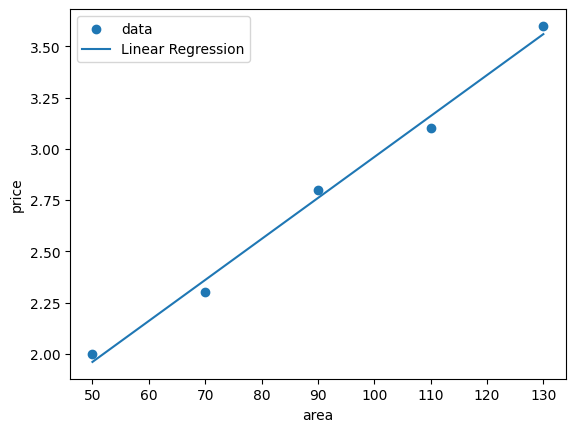

In [20]:
X = np.array([[50], [70], [90], [110], [130]])
y = np.array([2.0, 2.3, 2.8, 3.1, 3.6])

model = LinearRegression()
model.fit(X, y)
predictions = model.predict(X)

order = np.argsort(X[:, 0])

plt.scatter(X[:, 0], y, label="data")
plt.plot(
    X[order, 0],
    predictions[order],
    label="Linear Regression",
)
plt.xlabel("area")
plt.ylabel("price")
plt.legend()
plt.show()

### Residual Plot
Residual คือค่าที่โมเดลทำนายพลาด:

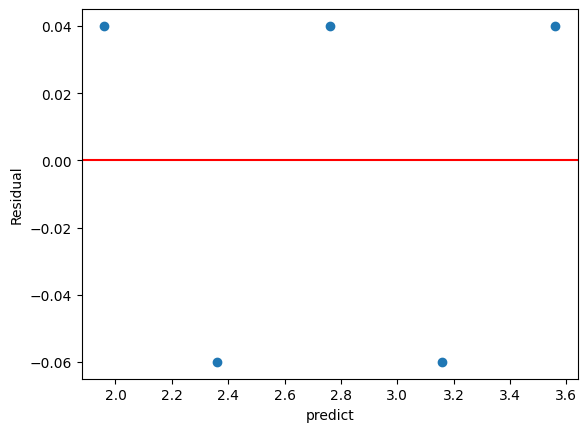

In [22]:
residuals = y - predictions

plt.scatter(predictions, residuals)
plt.axhline(0, color="red")
plt.xlabel("predict")
plt.ylabel("Residual")
plt.show()

### เปรียบเทียบด้วย Validation หรือ Cross-validation
ลองเปรียบเทียบ Linear Regression กับโมเดลที่จับความสัมพันธ์แบบโค้งได้ เช่น Decision Tree:

In [23]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

X = np.array([[50], [70], [90], [110], [130]])
y = np.array([2.0, 2.3, 2.8, 3.1, 3.6])

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

model = LinearRegression()

negative_mse = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="neg_mean_squared_error",
)

rmse_each_fold = np.sqrt(-negative_mse)
print("RMSE แต่ละ Fold:", rmse_each_fold)
print("RMSE เฉลี่ย:", rmse_each_fold.mean())

RMSE แต่ละ Fold: [0.08571429 0.1        0.05       0.1        0.08571429]
RMSE เฉลี่ย: 0.0842857142857143


### Correlation
ช่วยวัดความสัมพันธ์เชิงเส้น แต่ไม่สามารถบอกความสัมพันธ์ทุกชนิดได้
- ค่าใกล้ `1`: มีแนวโน้มเพิ่มไปด้วยกันแบบเชิงเส้น
- ค่าใกล้ `-1`: ตัวหนึ่งเพิ่ม อีกตัวมีแนวโน้มลดแบบเชิงเส้น
- ค่าใกล้ `0`: ไม่มีความสัมพันธ์เชิงเส้นชัดเจน แต่ยังอาจมีความสัมพันธ์แบบโค้ง

In [24]:
df = pd.DataFrame({
    "area": [50, 70, 90, 110, 130],
    "price": [2.0, 2.3, 2.8, 3.1, 3.6],
})

correlation = df["area"].corr(df["price"])
print(correlation)

0.9962709627734357


### แบ่งข้อมูลและประเมินโมเดลแบบครบขั้นตอน
ลำดับที่ควรจำคือ:
1. แบ่งข้อมูล
2. `fit()` ด้วย Train
3. `predict()` ด้วย Test
4. เปรียบเทียบค่าทำนายกับคำตอบจริง

In [25]:
X = np.array([
    [50], [60], [70], [80], [90],
    [100], [110], [120], [130], [140],
])
y = np.array([2.0, 2.1, 2.4, 2.5, 2.8, 3.0, 3.1, 3.4, 3.5, 3.8])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("ค่าจริง:", y_test)
print("ค่าทำนาย:", predictions)
print("Test RMSE:", rmse)

ค่าจริง: [3.5 2.1]
ค่าทำนาย: [3.575 2.175]
Test RMSE: 0.07499999999999996
